# Test v2: `ClusterPicker` (with charts)

This is the v2 version: it imports `cluster_picker_v2.py` directly and uses the built-in `plot_` methods for the charts. Each part ends with chart checks that call every `plot_` method.

This notebook uses two well-known datasets:

| Part | Dataset | Why it's a good test |
|---|---|---|
| **A** | **Mall Customers** (200 shoppers) | The classic customer-segmentation example. Annual income vs spending score has **5 visible groups**, so we know what the picker should find |
| **B** | **Palmer Penguins** (333 penguins) | We hide the species and see if clustering finds them. Passing `ground_truth="species"` lets us **score the clusters against reality**, which shows where the internal metrics mislead |

Each part ends with automatic checks that print **All checks passed**.

In [1]:
# --- Find the ML root folder and import the v2 picker (with charts) ---
import sys
from pathlib import Path

ml_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pickers").is_dir())
if str(ml_root) not in sys.path:
    sys.path.insert(0, str(ml_root))

%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pickers.cluster_picker_v2 import ClusterPicker
print("Using:", ml_root / "pickers" / "cluster_picker_v2.py")

Using: C:\data\GitHub\Model_Picker\pickers\cluster_picker_v2.py


# Part A: Mall Customers
## A1. Load the data

In [2]:
MALL_URL = "https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv"
mall = pd.read_csv(MALL_URL)
print(mall.shape, "| missing values:", mall.isna().sum().sum())
mall.head()

(200, 5) | missing values: 0


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## A2. Set up the picker
We cluster on **income and spending only**, the classic version of this exercise. `ignore=` leaves the other columns out of the clustering but keeps them in the DataFrame, so they still appear in `assign_clusters()`.

Creating the picker runs a K-Means scan of k = 2 to 10 to choose the starting number of clusters.

In [3]:
mall_cl = ClusterPicker(mall, ignore=["CustomerID", "Gender", "Age"])
print(mall_cl.summary())
mall_cl.k_scan()

Rows: 200   Features (encoded): 2
Categorical columns one-hot encoded: none
Starting n_clusters: 5 (searched 2..10)   DBSCAN eps: 0.313   min_samples: 4


,Inertia,Silhouette,Calinski-Harabasz,Davies-Bouldin,GMM BIC
k,,,,,
2,269.6910,0.3213,95.6694,1.2670,1153.9047
3,157.7040,0.4666,151.3351,0.7165,1151.7183
4,108.9213,0.4939,174.5952,0.7096,1103.7901
5,65.5684,0.5547,248.6493,0.5722,1058.6523
6,55.0573,0.5399,243.0879,0.6546,1074.6828
7,44.8648,0.5281,254.6212,0.7148,1087.3285
8,37.2282,0.4552,267.2790,0.7602,1102.3707
9,32.3923,0.4571,270.9484,0.7632,1106.8058
10,29.9819,0.4432,260.5403,0.7935,1127.6182


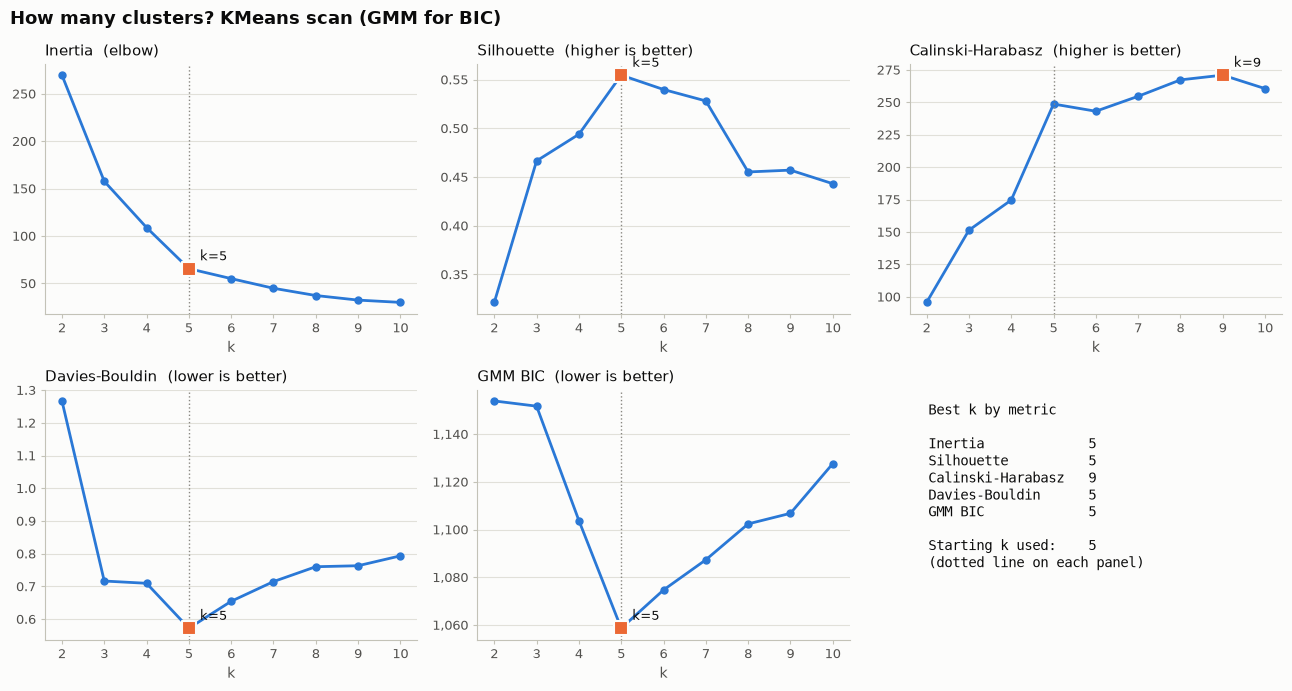

In [4]:
# The k-scan as charts: best k marked on each panel, the starting k as a dotted line
mall_cl.plot_k_scan();

## A3. Compare all models

In [5]:
%%time
mall_lb = mall_cl.compare_models()
mall_lb

Starting values: n_clusters=5, DBSCAN eps=0.313, min_samples=4, MeanShift bandwidth=1.047
  K-Means                  k=5   Silhouette=0.5547  (0.0s)
  Mini-Batch K-Means       k=5   Silhouette=0.5547  (0.0s)
  Bisecting K-Means        k=5   Silhouette=0.3842  (0.0s)
  Gaussian Mixture         k=5   Silhouette=0.5537  (0.0s)
  Agglomerative (Ward)     k=5   Silhouette=0.5538  (0.0s)
  BIRCH                    k=5   Silhouette=0.4145  (0.0s)
  Spectral Clustering      k=5   Silhouette=0.5175  (0.0s)
  Affinity Propagation     k=11  Silhouette=0.4422  (0.0s)
  DBSCAN                   k=7   Silhouette=0.4673  (0.0s)
  HDBSCAN                  k=6   Silhouette=0.4840  (0.0s)
  Mean Shift               k=3   Silhouette=0.4641  (0.0s)

Skipped: optics (turbo mode (set turbo=False to include))
CPU times: total: 969 ms
Wall time: 200 ms


,Model,Clusters,Noise %,Silhouette,Calinski-Harabasz,Davies-Bouldin,Mean rank,Fit (s),Note
ID,,,,,,,,,
kmeans,K-Means,5,0.0,0.5547,248.6493,0.5722,2.5000,0.0107,
mbkmeans,Mini-Batch K-Means,5,0.0,0.5547,248.6493,0.5722,2.5000,0.0164,
hclust,Agglomerative (Ward),5,0.0,0.5538,244.4103,0.5779,5.0000,0.0271,
gmm,Gaussian Mixture,5,0.0,0.5537,244.9402,0.5760,4.6667,0.0106,
spectral,Spectral Clustering,5,0.0,0.5175,230.6173,0.6313,6.3333,0.0085,
hdbscan,HDBSCAN,6,13.5,0.4840,245.1912,0.5130,3.6667,0.0030,
dbscan,DBSCAN,7,9.0,0.4673,209.9509,0.5308,5.6667,0.0012,
meanshift,Mean Shift,3,0.0,0.4641,150.1808,0.7230,9.3333,0.0477,
ap,Affinity Propagation,11,0.0,0.4422,266.4348,0.7130,6.3333,0.0158,


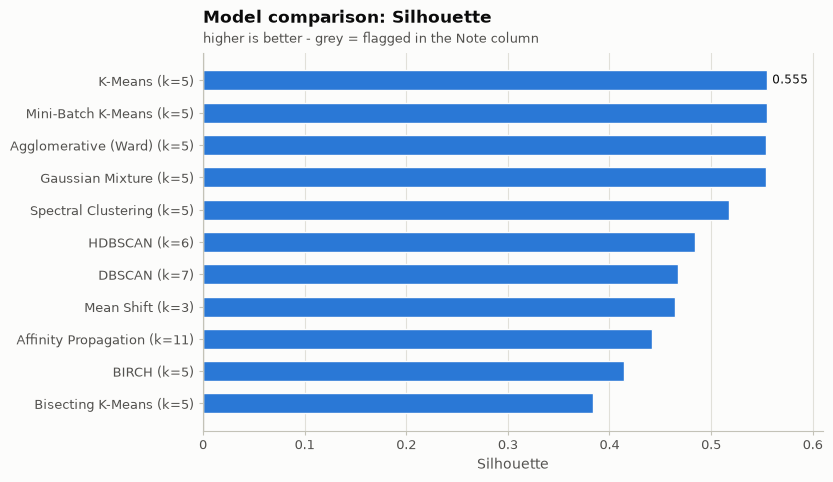

In [6]:
mall_cl.plot_leaderboard();

## A4. Tune the top 3

In [7]:
mall_tuned = mall_cl.tune_top(n=3, n_iter=20)
print(mall_cl.summary())
mall_tuned

  K-Means                  start=0.5547  tuned=0.5547  k=5  -> keep starting
  Mini-Batch K-Means       start=0.5547  tuned=0.5547  k=5  -> keep starting
  Agglomerative (Ward)     start=0.5538  tuned=0.5538  k=5  -> keep starting
Rows: 200   Features (encoded): 2
Categorical columns one-hot encoded: none
Starting n_clusters: 5 (searched 2..10)   DBSCAN eps: 0.313   min_samples: 4

Best model: K-Means (kmeans)  -  5 clusters, 0.0% noise
  Silhouette: 0.5547   Calinski-Harabasz: 248.6493   Davies-Bouldin: 0.5722
Recommended hyperparameters:
  n_clusters = 5
  n_init = 10


,Model,Silhouette (start),Silhouette (tuned),Kept,Clusters,Noise %,Calinski-Harabasz,Davies-Bouldin,Configs tried,Tune (s)
ID,,,,,,,,,,
kmeans,K-Means,0.5547,0.5547,starting,5,0.0,248.6493,0.5722,20,0.2447
mbkmeans,Mini-Batch K-Means,0.5547,0.5547,starting,5,0.0,248.6493,0.5722,20,0.3918
hclust,Agglomerative (Ward),0.5538,0.5538,starting,5,0.0,244.4103,0.5779,20,0.0933


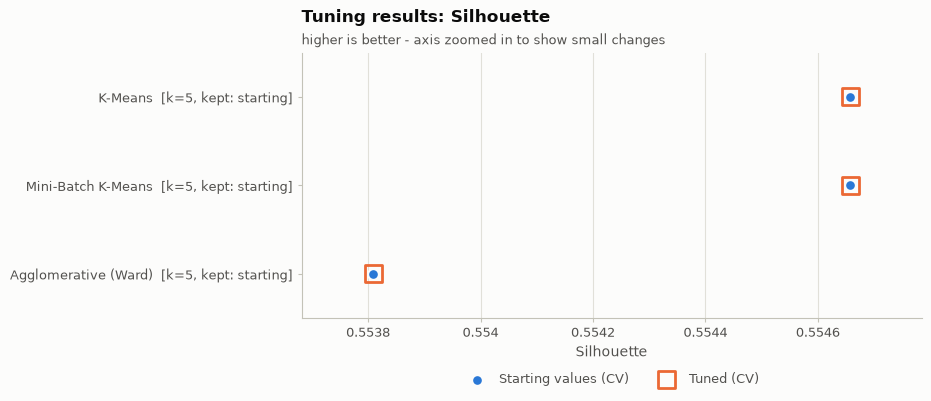

In [8]:
mall_cl.plot_tuning();

## A5. Profile the segments
This is the table you'd hand to a marketing manager: the size and average values of each cluster, in the original units.

In [9]:
best_mall = mall_cl.best_model_id()
mall_cl.profile(best_mall)

,Size,Share %,Annual Income (k$),Spending Score (1-100)
Cluster,,,,
0,81,40.5,55.296,49.519
1,39,19.5,86.538,82.128
2,22,11.0,25.727,79.364
3,35,17.5,88.200,17.114
4,23,11.5,26.304,20.913


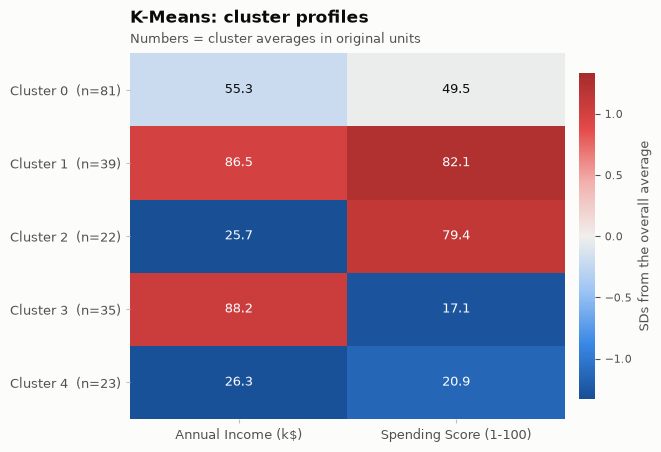

In [10]:
mall_cl.plot_profile();          # colour = above/below average, numbers = actual averages

With only two numeric columns, `plot_clusters()` uses the original axes. With more, it switches to a 2-D PCA view.

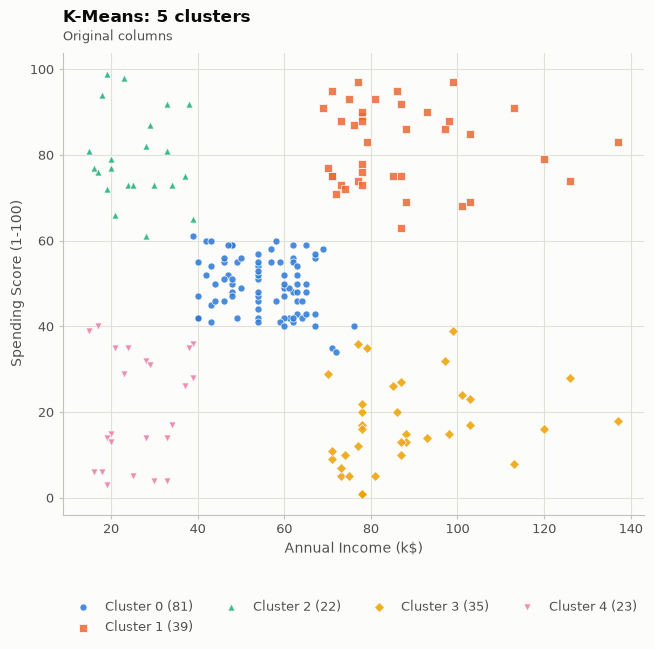

In [11]:
seg = mall_cl.assign_clusters(best_mall)
mall_cl.plot_clusters();

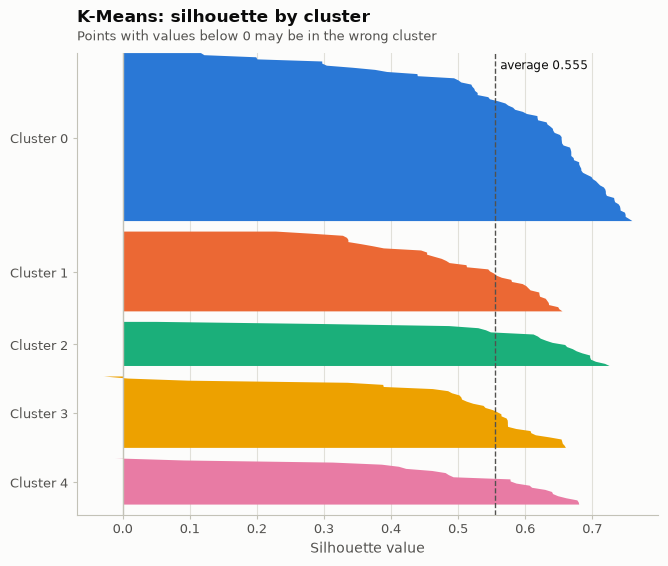

In [12]:
mall_cl.plot_silhouette();       # bars below 0 = points that may be in the wrong cluster

For comparison, DBSCAN finds its own number of clusters and marks outliers as **noise** (grey x).

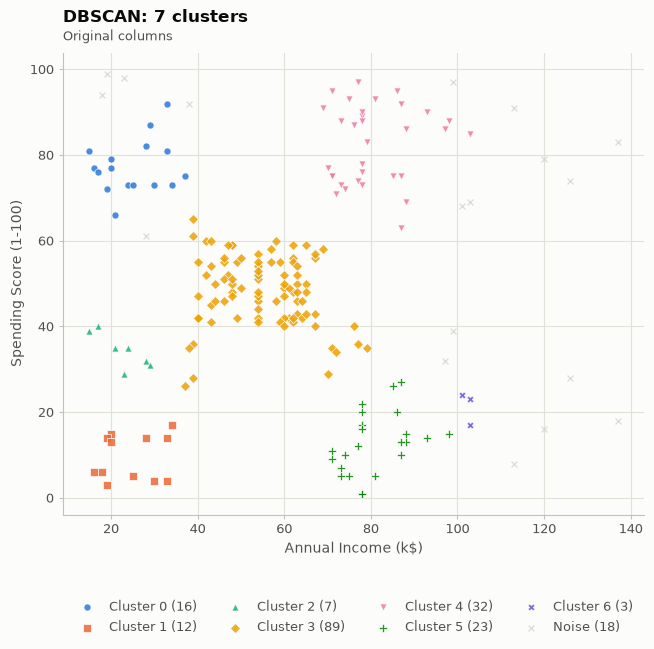

In [13]:
mall_cl.plot_clusters("dbscan");

## A6. Label new customers
Centroid models like K-Means can `.predict()` new rows. Density and hierarchical models can only label the data they were fitted on.

In [14]:
new_customers = pd.DataFrame({"Annual Income (k$)": [20, 90, 55], "Spending Score (1-100)": [85, 15, 50]})
mall_model = mall_cl.get_model(best_mall)
new_customers.assign(Cluster=mall_model.predict(new_customers))

,Annual Income (k$),Spending Score (1-100),Cluster
0,20,85,2
1,90,15,3
2,55,50,0


## A7. Automatic checks: Mall Customers

In [15]:
lb = mall_cl.leaderboard_
checks = {
    "k-scan picked 5 clusters":                      mall_cl.ctx.k == 5,
    "10+ models compared":                           len(lb) >= 10,
    "best model found 5 clusters with no noise":     mall_cl._score(mall_cl.labels(best_mall))["Clusters"] == 5
                                                     and mall_cl._score(mall_cl.labels(best_mall))["Noise %"] == 0,
    "best silhouette is above 0.5":                  mall_cl.tuned_.iloc[0, 1] > 0.5,
    "ignored columns kept in assign_clusters()":     {"CustomerID", "Gender", "Age", "Cluster"} <= set(seg.columns),
    "profile sizes add up to 200":                   mall_cl.profile(best_mall)["Size"].sum() == 200,
    "every model has recommended params":            all(m in mall_cl.recommended_params_ for m in mall_cl.tuned_.index),
    "new customers get a cluster label":             len(mall_model.predict(new_customers)) == 3,
}
for name, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + name)
assert all(checks.values()), "Some Mall checks failed - see above"
print("\nAll Mall checks passed")

PASS  k-scan picked 5 clusters
PASS  10+ models compared
PASS  best model found 5 clusters with no noise
PASS  best silhouette is above 0.5
PASS  ignored columns kept in assign_clusters()
PASS  profile sizes add up to 200
PASS  every model has recommended params
PASS  new customers get a cluster label

All Mall checks passed


## A8. Chart checks: Mall Customers

In [16]:
from matplotlib.axes import Axes
from matplotlib.figure import Figure

def run_chart_checks(calls, expect_errors=None):
    """Call every chart; PASS if it returns a matplotlib Axes/Figure without an error.
    expect_errors: {name: (callable, ExceptionType)} that SHOULD raise that error."""
    results = {}
    for name, call in calls.items():
        try:
            results[name] = isinstance(call(), (Axes, Figure))
        except Exception as e:
            print(f"  {name} -> {type(e).__name__}: {e}")
            results[name] = False
        finally:
            plt.close("all")
    for name, (call, err) in (expect_errors or {}).items():
        try:
            call()
            results[name] = False
        except err:
            results[name] = True
        except Exception as e:
            print(f"  {name} -> unexpected {type(e).__name__}: {e}")
            results[name] = False
        finally:
            plt.close("all")
    for name, ok in results.items():
        print(("PASS  " if ok else "FAIL  ") + name)
    return results


In [17]:
calls = {
    "plot_k_scan()":                           lambda: mall_cl.plot_k_scan(),
    "plot_leaderboard()":                      lambda: mall_cl.plot_leaderboard(),
    "plot_leaderboard(metric='Davies-Bouldin')": lambda: mall_cl.plot_leaderboard(metric="Davies-Bouldin"),
    "plot_tuning()":                           lambda: mall_cl.plot_tuning(),
    "plot_clusters() - original columns":      lambda: mall_cl.plot_clusters(),
    "plot_clusters('dbscan') - with noise":    lambda: mall_cl.plot_clusters("dbscan"),
    "plot_silhouette()":                       lambda: mall_cl.plot_silhouette(),
    "plot_silhouette('dbscan')":               lambda: mall_cl.plot_silhouette("dbscan"),
    "plot_profile()":                          lambda: mall_cl.plot_profile(),
    "plot_profile('dbscan') - noise row":      lambda: mall_cl.plot_profile("dbscan"),
}
expect = {
    "plot_crosstab() without ground_truth raises": (lambda: mall_cl.plot_crosstab(), ValueError),
    "plot_tuning() before tune_top() raises":      (lambda: ClusterPicker(mall, ignore=["CustomerID", "Gender", "Age"]).plot_tuning(), RuntimeError),
}
chart_results = run_chart_checks(calls, expect)
assert all(chart_results.values()), "Some Mall chart checks failed - see above"
print("\nAll Mall chart checks passed")

PASS  plot_k_scan()
PASS  plot_leaderboard()
PASS  plot_leaderboard(metric='Davies-Bouldin')
PASS  plot_tuning()
PASS  plot_clusters() - original columns
PASS  plot_clusters('dbscan') - with noise
PASS  plot_silhouette()
PASS  plot_silhouette('dbscan')
PASS  plot_profile()
PASS  plot_profile('dbscan') - noise row
PASS  plot_crosstab() without ground_truth raises
PASS  plot_tuning() before tune_top() raises

All Mall chart checks passed


# Part B: Palmer Penguins (do the clusters match the species?)
## B1. Load and clean
We cluster on the four body measurements only. `island` and `sex` are ignored, and `species` is passed as `ground_truth`: it's **never used for clustering**, only to score the result afterwards.

In [18]:
PENGUIN_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
penguins = pd.read_csv(PENGUIN_URL).dropna().reset_index(drop=True)
print("Rows:", len(penguins))

peng_cl = ClusterPicker(penguins, ground_truth="species", ignore=["island", "sex"])
peng_cl.k_scan()

Rows: 333


,Inertia,Silhouette,Calinski-Harabasz,Davies-Bouldin,GMM BIC
k,,,,,
2,552.6710,0.5308,466.7476,0.7153,2523.8761
3,370.7661,0.4462,427.7726,0.9420,2495.4524
4,293.9048,0.3982,387.3515,0.9443,2555.8127
5,228.5065,0.3744,395.9909,0.9777,2601.5477
6,200.2827,0.3642,369.5492,0.9992,2658.6733
7,183.0409,0.3287,341.0536,1.0773,2718.9563
8,167.1392,0.2992,323.5794,1.1413,2805.1478
9,155.2861,0.2884,306.8976,1.2017,2860.4186
10,145.9004,0.2871,291.7593,1.2094,2903.5944


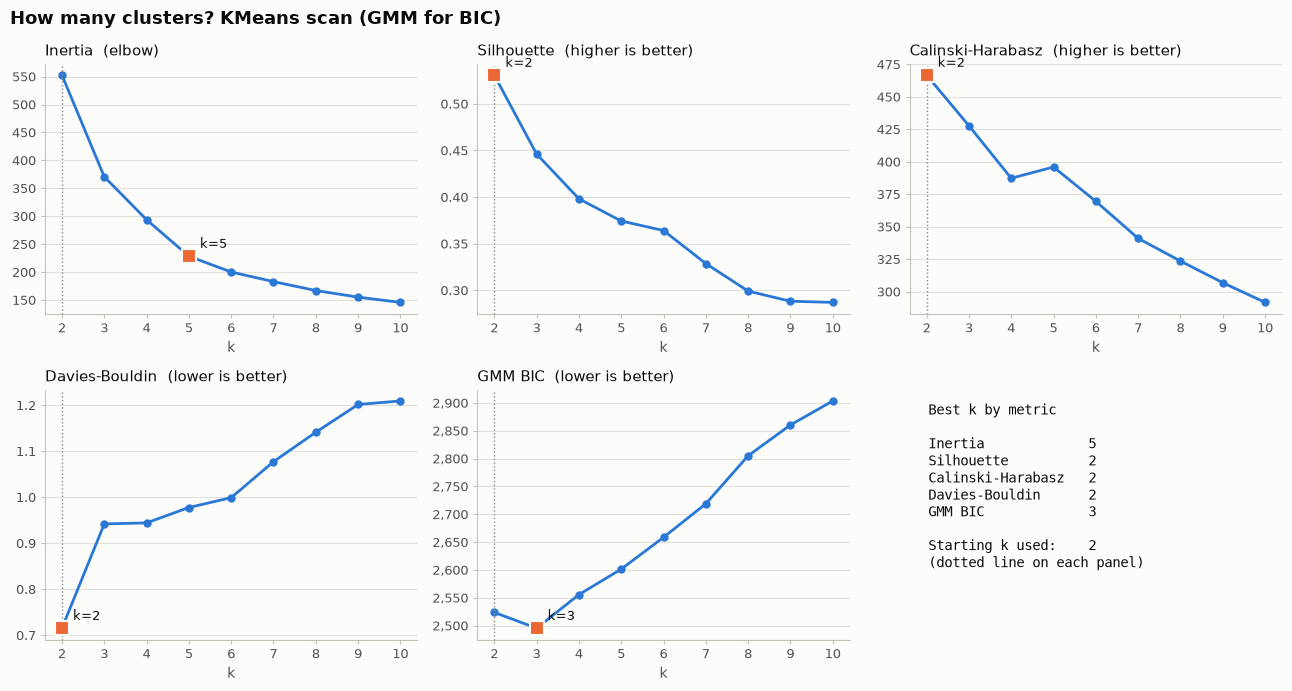

In [19]:
peng_cl.plot_k_scan();           # silhouette, CH and DB say 2 - only BIC says 3

Notice the disagreement: **silhouette, Calinski-Harabasz and Davies-Bouldin all prefer k = 2, but GMM BIC prefers k = 3**.
Gentoo penguins are very different from the other two species, while Adelie and Chinstrap overlap. So the "roundest" split is 2 groups, even though there are 3 species.

In [20]:
peng_lb = peng_cl.compare_models(verbose=False)
peng_lb[["Model", "Clusters", "Noise %", "Silhouette", "Mean rank", "ARI", "NMI", "Note"]]

,Model,Clusters,Noise %,Silhouette,Mean rank,ARI,NMI,Note
ID,,,,,,,,
kmeans,K-Means,2,0.0000,0.5308,5.3333,0.6486,0.7644,
mbkmeans,Mini-Batch K-Means,2,0.0000,0.5308,5.3333,0.6486,0.7644,
bkmeans,Bisecting K-Means,2,0.0000,0.5308,5.3333,0.6486,0.7644,
gmm,Gaussian Mixture,2,0.0000,0.5308,5.3333,0.6486,0.7644,
hclust,Agglomerative (Ward),2,0.0000,0.5308,5.3333,0.6486,0.7644,
birch,BIRCH,2,0.0000,0.5308,5.3333,0.6486,0.7644,
spectral,Spectral Clustering,2,0.0000,0.5308,5.3333,0.6486,0.7644,
hdbscan,HDBSCAN,2,0.6006,0.5302,4.0000,0.6460,0.7494,
dbscan,DBSCAN,2,2.7027,0.5253,3.6667,0.6355,0.7056,


## B2. Use domain knowledge: set k = 3
If you know there should be 3 groups, set `n_clusters=3`. Sorting by **ARI** (agreement with the true species; 1 = perfect, 0 = random) shows which model recovers them best.
In a real project you wouldn't have ground truth. This is a teaching exercise that shows the internal metrics alone can miss the real structure.

In [21]:
peng3 = ClusterPicker(penguins, ground_truth="species", ignore=["island", "sex"], n_clusters=3, sort="ARI")
peng3_lb = peng3.compare_models(verbose=False)
peng3_lb[["Model", "Clusters", "Silhouette", "ARI", "NMI", "Homogeneity"]]

,Model,Clusters,Silhouette,ARI,NMI,Homogeneity
ID,,,,,,
birch,BIRCH,3,0.4457,0.9834,0.9720,0.9698
gmm,Gaussian Mixture,3,0.4527,0.9590,0.9337,0.9326
spectral,Spectral Clustering,3,0.4573,0.9434,0.9188,0.9134
hclust,Agglomerative (Ward),3,0.4521,0.9132,0.8989,0.8864
mbkmeans,Mini-Batch K-Means,3,0.4568,0.8971,0.8643,0.8670
meanshift,Mean Shift,4,0.4258,0.8041,0.7889,0.8058
kmeans,K-Means,3,0.4462,0.7994,0.7899,0.8012
bkmeans,Bisecting K-Means,3,0.4462,0.7994,0.7899,0.8012
hdbscan,HDBSCAN,2,0.5302,0.6460,0.7494,0.6180


In [22]:
peng3.tune_top(n=3, n_iter=20, verbose=False)
best_peng = peng3.best_model_id()
print(peng3.summary())
peng3.profile(best_peng)

Rows: 333   Features (encoded): 4
Categorical columns one-hot encoded: none
Starting n_clusters: 3 (searched 2..10)   DBSCAN eps: 0.783   min_samples: 8

Best model: BIRCH (birch)  -  3 clusters, 0.0% noise
  Silhouette: 0.4457   Calinski-Harabasz: 402.3899   Davies-Bouldin: 0.9205   ARI: 0.9834   NMI: 0.9720   Homogeneity: 0.9698
Recommended hyperparameters:


,Size,Share %,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,Most common label
Cluster,,,,,,,
0,148,44.444,38.880,18.339,190.122,3703.378,Adelie
1,119,35.736,47.568,14.997,217.235,5092.437,Gentoo
2,66,19.820,49.012,18.442,195.955,3740.152,Chinstrap


In [23]:
# How the clusters line up with the real species
pd.crosstab(penguins["species"], peng3.labels(best_peng), rownames=["species"], colnames=["cluster"])

cluster,0,1,2
species,,,
Adelie,146,0,0
Chinstrap,2,0,66
Gentoo,0,119,0


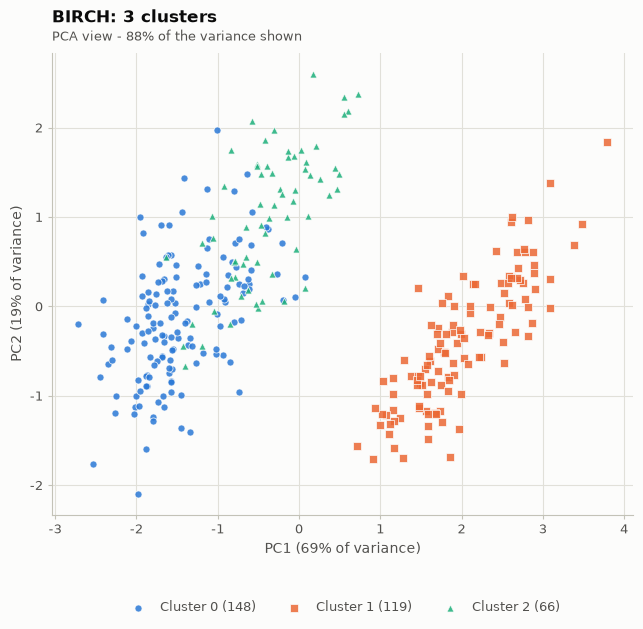

In [24]:
peng3.plot_clusters();           # 4 measurements, so this is a 2-D PCA view

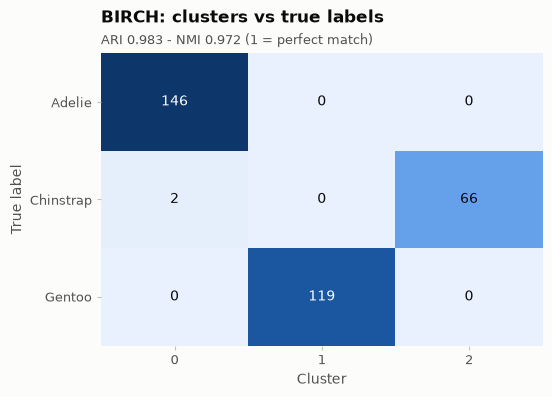

In [25]:
peng3.plot_crosstab();           # clusters vs the real species

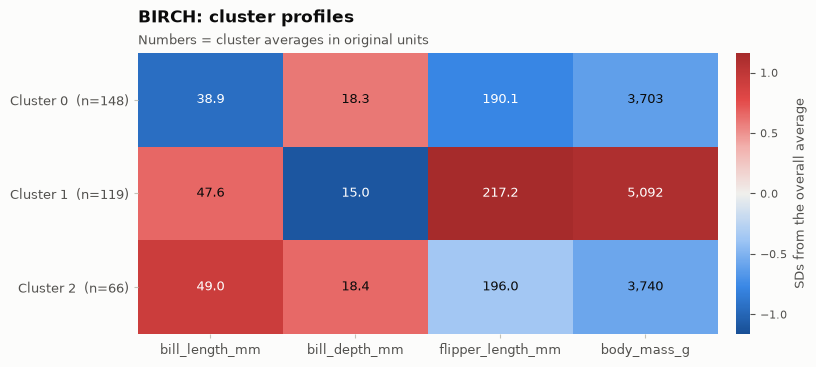

In [26]:
peng3.plot_profile();

## B3. Automatic checks: penguins

In [27]:
checks = {
    "silhouette scan prefers k = 2":                   peng_cl.ctx.k == 2,
    "GMM BIC prefers k = 3":                           peng_cl.k_scan()["GMM BIC"].idxmin() == 3,
    "ground truth column not used as a feature":       "species" not in peng_cl.X.columns,
    "ARI/NMI/Homogeneity columns present":             {"ARI", "NMI", "Homogeneity"} <= set(peng_lb.columns),
    "with k = 3, best ARI is above 0.85":              peng3_lb["ARI"].max() > 0.85,
    "k = 3 beats k = 2 on ARI":                        peng3_lb["ARI"].max() > peng_lb["ARI"].max(),
    "profile shows the most common species":           "Most common label" in peng3.profile(best_peng).columns,
}

# Error handling
try:
    ClusterPicker(pd.read_csv(PENGUIN_URL), ignore=["species"])      # raw data has NaNs
    checks["missing values are rejected"] = False
except ValueError:
    checks["missing values are rejected"] = True
try:
    ClusterPicker(penguins.drop(columns="species"), sort="ARI")      # ARI needs ground truth
    checks["ARI sort without ground_truth is rejected"] = False
except ValueError:
    checks["ARI sort without ground_truth is rejected"] = True

for name, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + name)
assert all(checks.values()), "Some penguin checks failed - see above"
print("\nAll checks passed")

PASS  silhouette scan prefers k = 2
PASS  GMM BIC prefers k = 3
PASS  ground truth column not used as a feature
PASS  ARI/NMI/Homogeneity columns present
PASS  with k = 3, best ARI is above 0.85
PASS  k = 3 beats k = 2 on ARI
PASS  profile shows the most common species
PASS  missing values are rejected
PASS  ARI sort without ground_truth is rejected

All checks passed


## B4. Chart checks: penguins

In [28]:
calls = {
    "plot_k_scan()":                      lambda: peng_cl.plot_k_scan(),
    "plot_leaderboard(metric='ARI')":     lambda: peng3.plot_leaderboard(metric="ARI"),
    "plot_tuning()":                      lambda: peng3.plot_tuning(),
    "plot_clusters() - PCA view":         lambda: peng3.plot_clusters(),
    "plot_silhouette()":                  lambda: peng3.plot_silhouette(),
    "plot_profile()":                     lambda: peng3.plot_profile(),
    "plot_crosstab()":                    lambda: peng3.plot_crosstab(),
    "plot_crosstab('kmeans')":            lambda: peng3.plot_crosstab("kmeans"),
}
chart_results = run_chart_checks(calls)
assert all(chart_results.values()), "Some penguin chart checks failed - see above"
print("\nAll checks passed")

PASS  plot_k_scan()
PASS  plot_leaderboard(metric='ARI')
PASS  plot_tuning()
PASS  plot_clusters() - PCA view
PASS  plot_silhouette()
PASS  plot_profile()
PASS  plot_crosstab()
PASS  plot_crosstab('kmeans')

All checks passed
